# Practical 12: SVM – Handwritten Digit Recognition

**Aim:** To implement SVM with Linear and RBF kernels on the MNIST dataset and compare their performance.

**Dataset:** [MNIST Digit Recognizer – Kaggle](https://www.kaggle.com/competitions/digit-recognizer/data)

Download `train.csv` from Kaggle and keep it in the same folder as this notebook.

**Note:** The full dataset is large. To keep the practical simple and reduce training time, this notebook uses the first 5,000 rows.

In [3]:
# Packages for analysis
import os
import numpy as np
import pandas as pd

# Packages for visuals
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Fallback dataset for local execution without Kaggle files
from sklearn.datasets import load_digits


In [4]:
# Read the MNIST data or use a local fallback if the Kaggle CSV is unavailable
data_path = "train.csv"
if os.path.exists(data_path):
    digits = pd.read_csv(data_path)
else:
    digits_raw = load_digits()
    digits = pd.DataFrame(
        digits_raw.data,
        columns=[f"pixel_{i}" for i in range(digits_raw.data.shape[1])],
    )
    digits["label"] = digits_raw.target
    print("Kaggle train.csv not found; using the sklearn digits dataset as a local fallback.")

digits = digits.head(5000).copy()
digits.head()


Kaggle train.csv not found; using the sklearn digits dataset as a local fallback.


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,label
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


In [5]:
# Use a small sample to reduce training time
digits = digits.head(5000)

digits.shape

(1797, 65)

In [6]:
# Each digit count
digits.label.value_counts()

label
3    183
1    182
5    182
4    181
6    181
9    180
7    179
0    178
2    177
8    174
Name: count, dtype: int64

In [7]:
# Specify inputs and output
X = digits.drop("label", axis=1)
y = digits["label"]

X[:3]

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_54,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0


In [8]:
y[:3]

0    0
1    1
2    2
Name: label, dtype: int64

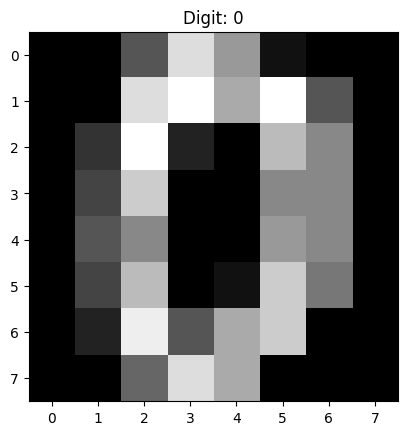

In [9]:
# Display one handwritten digit
image_size = int(np.sqrt(X.shape[1]))
plt.imshow(X.iloc[0].values.reshape(image_size, image_size), cmap="gray")
plt.title("Digit: " + str(y.iloc[0]))
plt.show()


In [10]:
# Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [11]:
# Scale pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

In [12]:
# Import SVM
from sklearn.svm import SVC

In [13]:
# Fit SVM model with Linear kernel
model1 = SVC(kernel="linear")
model1.fit(X_train, y_train)

SVC(kernel='linear')

In [14]:
# Check Linear SVM accuracy
model1.score(X_test, y_test) * 100

88.05555555555556

In [15]:
# Fit SVM model with RBF kernel
model2 = SVC(kernel="rbf")
model2.fit(X_train, y_train)

SVC()

In [16]:
# Check RBF SVM accuracy
model2.score(X_test, y_test) * 100

99.16666666666667

In [17]:
# Compare both models
print("Linear Kernel Accuracy:", model1.score(X_test, y_test) * 100)
print("RBF Kernel Accuracy:", model2.score(X_test, y_test) * 100)

Linear Kernel Accuracy: 88.05555555555556
RBF Kernel Accuracy: 99.16666666666667


In [18]:
# Predict digits
y_pred = model2.predict(X_test)
y_pred[:10]

array([5, 2, 8, 1, 7, 2, 6, 2, 6, 5])

In [19]:
# Actual digits
y_test[:10]

618     5
1427    2
158     8
1256    1
1079    7
648     2
1773    6
1531    2
1063    6
781     5
Name: label, dtype: int64

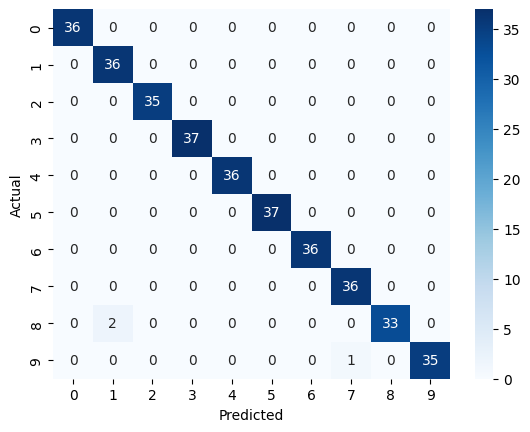

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      1.00      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       0.97      1.00      0.99        36
           8       1.00      0.94      0.97        35
           9       1.00      0.97      0.99        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



In [20]:
# Confusion matrix
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, y_pred))

## Conclusion

SVM was implemented on the MNIST handwritten digit dataset using Linear and RBF kernels. Their testing accuracies were compared to evaluate their performance in recognizing handwritten digits.